# Unified Logarithmic Potential

This notebook applies the Metropolis–Hastings exchange from `05_log_potential.ipynb` with the unified potential

$$U(w) = A\log\left(1 + \frac{w}{w_0}\right).$$

For $w \ll w_0$ the potential is approximately linear, $U(w) \approx A w / w_0$, so the bulk of the distribution behaves like the exponential DY regime. For $w \gg w_0$ it is logarithmic, which produces a power-law tail. The scale $w_0$ sets where the crossover happens, and $A$ sets the steepness of the tail.

The one-agent Gibbs weight is

$$e^{-\beta U(w)} = \left(1 + \frac{w}{w_0}\right)^{-\beta A},$$

a Lomax (Pareto Type II) density. For large $w$, $p(w) \sim w^{-\beta A}$, so the CCDF decays as $P(W > w) \sim w^{-(\beta A - 1)}$.

Total wealth is conserved, which matters here. For $\beta A > 2$ there is a critical mean wealth $\rho_c = w_0 / (\beta A - 2)$. Below it the tail is exponentially tilted, and above it the excess wealth condenses onto a single agent. The parameters are therefore chosen to sit exactly at criticality, where the stationary marginal is the untilted Lomax law:

- $\bar w = 1$ (mean wealth), $\beta = 1$, $A = 2.5$, $w_0 = 0.5$, giving $\rho_c = 0.5 / 0.5 = 1 = \bar w$
- Theoretical tail: $p(w) \sim w^{-2.5}$, CCDF $\sim w^{-1.5}$

The simulation is run twice, once from uniform initial wealth and once from exponential initial wealth, to show that the stationary distribution does not depend on the starting point.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from wealth_dist.plotting import plot_simulation_results, prepare_ccdf
from wealth_dist.metropolis import MH_simulate
from wealth_dist.stats_analysis import pareto_tail_fits

np.random.seed()  # for reproducibility

In [2]:
N = 5000 # agents
m = 1 # mean wealth
sims = 10**7
beta = 1
A = 2.5
w0 = 0.5

def U(w):
    return A * np.log1p(w / w0)

uniform_res = MH_simulate(N, m, sims, count = 0.01, beta = beta, U = U, uniform = True)
exp_res = MH_simulate(N, m, sims, count = 0.01, beta = beta, U = U, uniform = False)

The wealth histogram and entropy over time for each starting distribution. The entropy levels off in both cases.

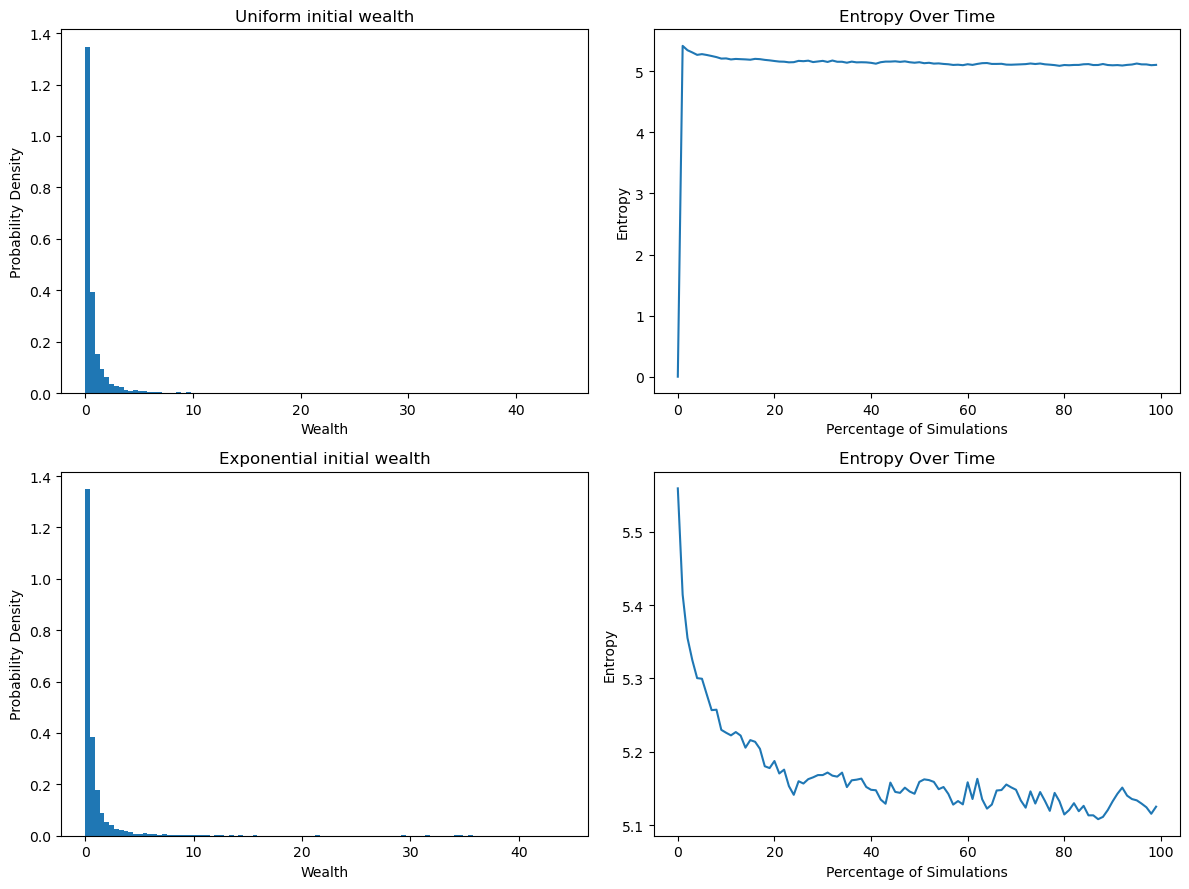

In [3]:
fig, axs = plt.subplots(2, 2, figsize=(12, 9))
plot_simulation_results(uniform_res, bins = 100, title = "Uniform initial wealth", ax = axs[0, :])
plot_simulation_results(exp_res, bins = 100, title = "Exponential initial wealth", ax = axs[1, :])
plt.tight_layout()
plt.show()

### Tail

The CCDF of both runs against the theoretical Lomax CCDF $P(W > w) = (1 + w/w_0)^{-(\beta A - 1)}$, on semi-log axes (bulk) and log-log axes (tail). On log-log axes the tail should run parallel to the dashed line of slope $-(\beta A - 1) = -1.5$.

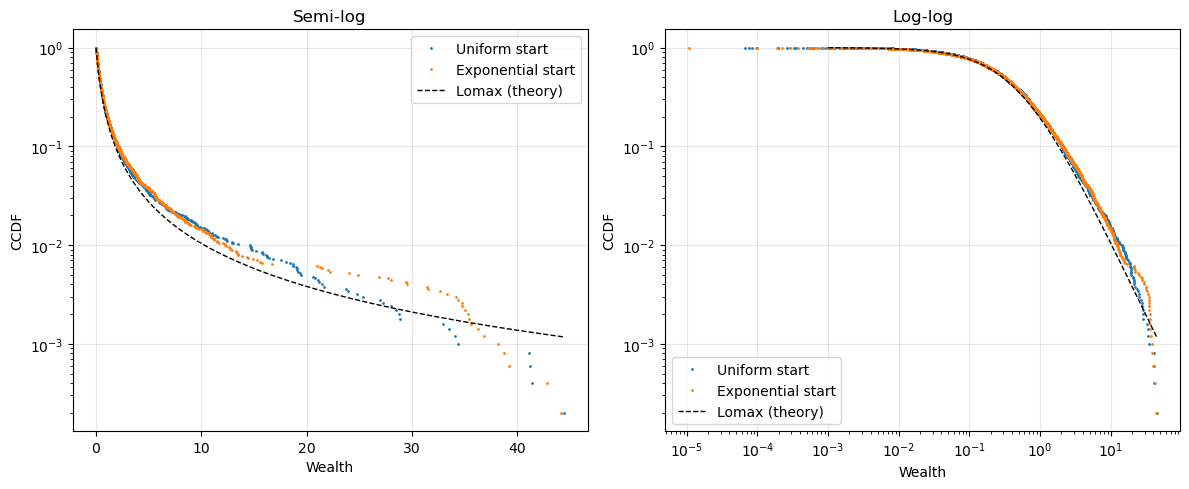

In [4]:
fig, axs = plt.subplots(1, 2, figsize=(12, 5))
alpha_ccdf = beta * A - 1

for ax, (xlog, title) in zip(axs, [(False, "Semi-log"), (True, "Log-log")]):
    for res, label in [(uniform_res, "Uniform start"), (exp_res, "Exponential start")]:
        x, ccdf = prepare_ccdf(res[0])
        ax.plot(x, ccdf, ".", ms = 2, label = label)
    xs = np.logspace(-3, np.log10(max(uniform_res[0].max(), exp_res[0].max())), 300)
    ax.plot(xs, (1 + xs / w0) ** (-alpha_ccdf), "k--", lw = 1, label = "Lomax (theory)")
    ax.set_yscale("log")
    if xlog:
        ax.set_xscale("log")
    ax.set_xlabel("Wealth")
    ax.set_ylabel("CCDF")
    ax.set_title(title)
    ax.grid(True, alpha = 0.3)
    ax.legend()

plt.tight_layout()
plt.show()

Pareto fits to the upper tail of each run. `alpha` is the exponent of the fitted CCDF, to compare with the theoretical value $\beta A - 1 = 1.5$.

In [5]:
print("Uniform initial wealth")
uniform_fits = pareto_tail_fits(uniform_res[0])
print("\n\nExponential initial wealth")
exp_fits = pareto_tail_fits(exp_res[0])

Uniform initial wealth

Top 10% tail
xmin = 2.0483851987232575
n_tail = 500
alpha = 1.271542007285853
KS = 0.036299495698711826
p-value = 0.5135328704910037

Top 5% tail
xmin = 3.540544655075554
n_tail = 250
alpha = 1.29667391864974
KS = 0.06689452329225709
p-value = 0.20388388891702358

Top 2.5% tail
xmin = 6.51594836114196
n_tail = 125
alpha = 1.4949948299736548
KS = 0.10848669512012873
p-value = 0.09785149339083465

Top 1% tail
xmin = 13.459990919828918
n_tail = 50
alpha = 2.5690166892788833
KS = 0.11073273708363834
p-value = 0.5354619187342715


Exponential initial wealth

Top 10% tail
xmin = 2.0808548943652183
n_tail = 500
alpha = 1.2403084248319725
KS = 0.04541342531249115
p-value = 0.24624986631230095

Top 5% tail
xmin = 3.8599154937175544
n_tail = 250
alpha = 1.3935098340219618
KS = 0.0684093646030956
p-value = 0.18386768999106184

Top 2.5% tail
xmin = 6.597252901791778
n_tail = 125
alpha = 1.5246335697548208
KS = 0.07553709782450824
p-value = 0.451693580956104

Top 1% tail
xmi

Both starting distributions give the same stationary CCDF, which follows the Lomax curve: the bulk is approximately exponential (below $w \approx w_0$) and it crosses over into a power-law tail. The fitted CCDF exponents settle around the theoretical value of 1.5 for the top 5% and 2.5%. The steeper fall-off at the very top (top 1%, roughly $w > 30$) is a finite-size effect: with $N = 5000$ agents, conserved total wealth and exchanges of at most $\bar w$ per step, the extreme tail has not fully filled in.